# 07 - Pattern finding: dimensions, distances, risk zones, label propagation, feature selection
**Heat, Rain & Harvest.** Phase 7. Unit = district (one row each), built by `src/profiles.py` from **1997-2017 only**,
so nothing here uses the 2018-2022 test years.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import MDS, TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score, balanced_accuracy_score
from sklearn.metrics.pairwise import euclidean_distances, cosine_similarity
from sklearn.semi_supervised import LabelSpreading
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupKFold
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.cluster.hierarchy import linkage, dendrogram
from src.config import PROCESSED, FIGURES, SEED, TRAIN_LAST_YEAR
from src.boundaries import load_pc11_districts
from src.features import detrend_train_only
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
save = lambda fig, n: fig.savefig(FIGURES / f"{n}.png", bbox_inches="tight", dpi=150)
geo = load_pc11_districts()
P = pd.read_parquet(PROCESSED / "district_profiles.parquet")
W = P.dropna(subset=["yield_mean"]).copy()                     # districts with a wheat profile
W["irr_mean"] = W.irr_mean.fillna(W.irr_mean.median())          # 17 districts lack irrigation data: median (noted)
cols = ["hot_days_mean", "tmin_mean", "rain_cv", "yield_mean", "yield_trend_kg", "anom_sd", "loss_share", "heat_sens", "irr_mean"]
X = StandardScaler().fit_transform(W[cols])                    # z-score every column: equal footing for distances
print(f"{len(W)} wheat districts x {len(cols)} features")

368 wheat districts x 9 features


## 1. PCA: which directions explain most of the differences between districts?
PCA finds new axes (principal components) that are uncorrelated and ordered by how much variance they explain.
Each component is a weighted sum of the standardised features; the weights are the **loadings**.

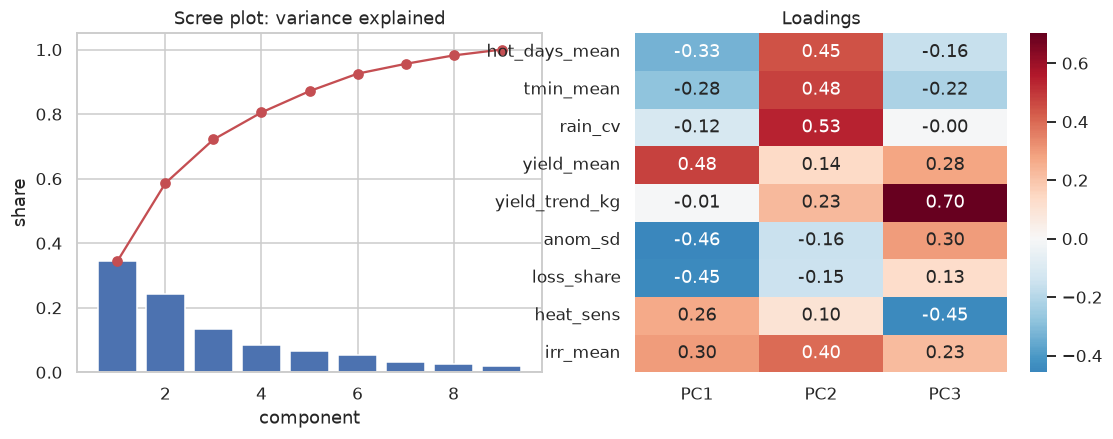

explained variance: [0.344 0.242 0.135 0.084]  cumulative PC1-3: 0.721


In [2]:
pca = PCA(random_state=SEED).fit(X)
ev = pca.explained_variance_ratio_
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(range(1, len(ev)+1), ev); ax[0].plot(range(1, len(ev)+1), ev.cumsum(), "ro-")
ax[0].set(title="Scree plot: variance explained", xlabel="component", ylabel="share")
L = pd.DataFrame(pca.components_[:3].T, index=cols, columns=["PC1", "PC2", "PC3"])
sns.heatmap(L, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[1]); ax[1].set_title("Loadings")
save(fig, "07_pca_scree_loadings"); plt.show()
print("explained variance:", np.round(ev[:4], 3), " cumulative PC1-3:", round(ev[:3].sum(), 3))
Z = pca.transform(X)
W[["PC1", "PC2"]] = Z[:, :2]

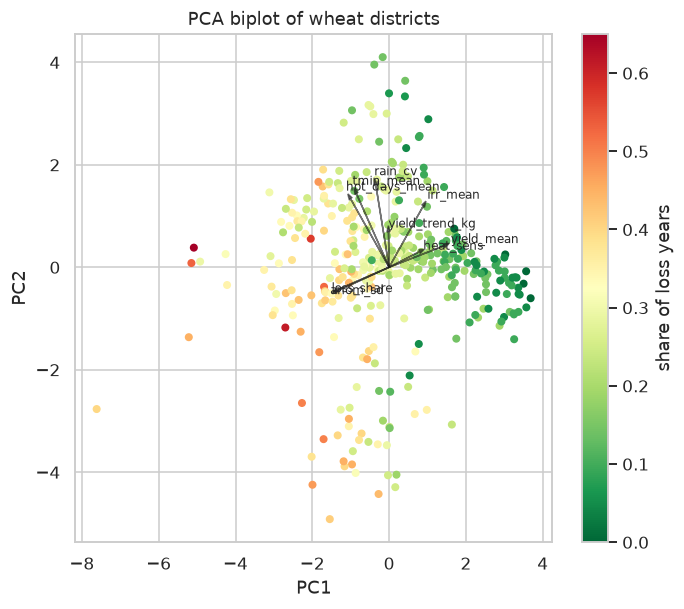

In [3]:
fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(W.PC1, W.PC2, c=W.loss_share, cmap="RdYlGn_r", s=18)
for c, (x, y) in zip(cols, pca.components_[:2].T * 3):          # biplot arrows: feature directions
    ax.arrow(0, 0, x, y, color="k", alpha=.6, head_width=.08); ax.text(x*1.12, y*1.12, c, fontsize=8)
plt.colorbar(sc, label="share of loss years"); ax.set(title="PCA biplot of wheat districts", xlabel="PC1", ylabel="PC2")
save(fig, "07_pca_biplot"); plt.show()

## 2. Distance and similarity
- **Euclidean distance** on standardised features: how different two districts' whole profiles are.
- **Cosine similarity**: angle between profile vectors (pattern, ignoring overall size).
Example: which districts are most similar to Ludhiana?

In [4]:
D = euclidean_distances(X); S = cosine_similarity(X)
i = W.index.get_loc(W.index[W.d_name == "Ludhiana"][0])
nn = pd.DataFrame({"district": W.d_name, "euclid": D[i], "cosine": S[i]}).sort_values("euclid").iloc[1:7]
print("Nearest to Ludhiana:"); print(nn.round(3).to_string(index=False))

Nearest to Ludhiana:
   district  euclid  cosine
    Patiala   0.642   0.987
  Jalandhar   0.648   0.988
   Amritsar   0.648   0.990
       Moga   0.723   0.983
Kurukshetra   0.816   0.986
 Kapurthala   0.821   0.981


## 3. MDS and t-SNE: 2-D maps of similarity
- **MDS** (metric): places points in 2-D so that map distances match the original distances as closely as possible (minimises *stress*).
- **t-SNE**: keeps *local neighbourhoods* (who is near whom); distances between far-apart groups are not meaningful.
  Depends on `perplexity` (roughly, number of neighbours considered) and the random seed.

/home/hpmehtaabkohli/miniconda3/envs/hrh/lib/python3.12/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/home/hpmehtaabkohli/miniconda3/envs/hrh/lib/python3.12/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


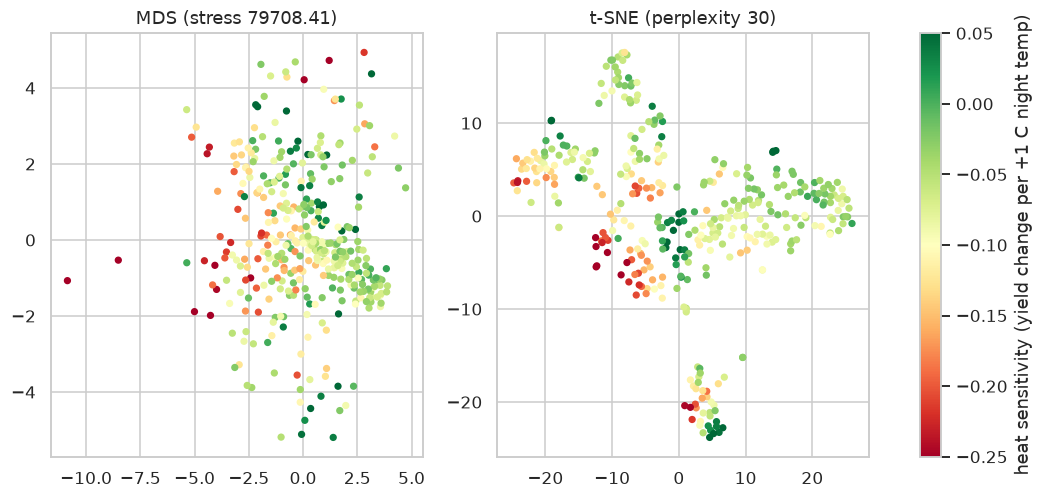

In [5]:
mds = MDS(n_components=2, dissimilarity="precomputed", random_state=SEED, normalized_stress="auto").fit(D)
tsne = TSNE(n_components=2, perplexity=30, random_state=SEED, init="pca").fit_transform(X)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, E, t in ((ax[0], mds.embedding_, f"MDS (stress {mds.stress_:.2f})"), (ax[1], tsne, "t-SNE (perplexity 30)")):
    s = a.scatter(E[:, 0], E[:, 1], c=W.heat_sens, cmap="RdYlGn", s=14, vmin=-.25, vmax=.05); a.set_title(t)
plt.colorbar(s, ax=ax, label="heat sensitivity (yield change per +1 C night temp)")
save(fig, "07_mds_tsne"); plt.show()

## 4. Clustering into risk zones
**k-means**: choose k centres, assign each district to the nearest, move centres to the mean, repeat.
Pick k with the **silhouette** score (how much closer a point is to its own cluster than to the next one; -1..1)
and the **elbow** of within-cluster sum of squares. Check stability against **hierarchical (Ward)** clustering with the
adjusted Rand index (ARI: 1 = identical partitions, 0 = chance agreement).

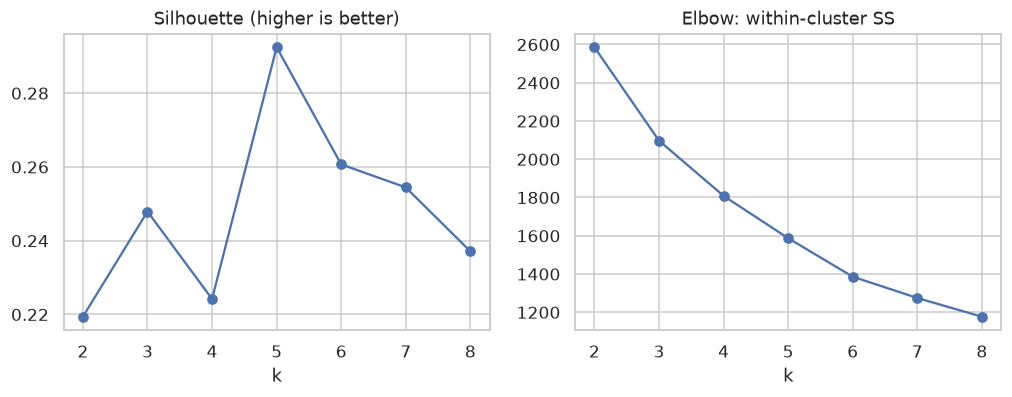

{2: np.float64(0.219), 3: np.float64(0.248), 4: np.float64(0.224), 5: np.float64(0.292), 6: np.float64(0.261), 7: np.float64(0.254), 8: np.float64(0.237)}


In [6]:
ks = range(2, 9); sil, inert = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X)
    sil.append(silhouette_score(X, km.labels_)); inert.append(km.inertia_)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(ks, sil, "o-"); ax[0].set(title="Silhouette (higher is better)", xlabel="k")
ax[1].plot(ks, inert, "o-"); ax[1].set(title="Elbow: within-cluster SS", xlabel="k")
save(fig, "07_choose_k"); plt.show()
print(dict(zip(ks, np.round(sil, 3))))

In [7]:
K = int(ks[int(np.argmax(sil))])   # k with the best silhouette score (DECISIONS D17)
print("chosen k =", K)
km = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit(X)
W["zone_raw"] = km.labels_
ward = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(X)
print(f"silhouette k={K}: {silhouette_score(X, km.labels_):.3f};  ARI k-means vs Ward: {adjusted_rand_score(km.labels_, ward.labels_):.3f}")
prof = W.groupby("zone_raw")[cols].mean()
# name zones by their profile: order by loss share (risk)
order = prof.loss_share.sort_values().index
names = {}
for rank, z in enumerate(order):
    row = prof.loc[z]
    tag = "high irrigation" if row.irr_mean > .8 else ("low irrigation" if row.irr_mean < .5 else "mixed irrigation")
    heat = "hot March" if row.hot_days_mean > W.hot_days_mean.median() else "mild March"
    names[z] = f"Zone {rank+1} (loss years {row.loss_share:.0%}): {heat}, {tag}"   # zones ordered by observed loss share
W["zone"] = W.zone_raw.map(names)
print(prof.rename(index=names).round(2).T.to_string())
print(W.zone.value_counts().to_string())

chosen k = 5


silhouette k=5: 0.292;  ARI k-means vs Ward: 0.606
zone_raw        Zone 4 (loss years 31%): mild March, low irrigation  Zone 1 (loss years 15%): mild March, high irrigation  Zone 3 (loss years 30%): hot March, mixed irrigation  Zone 2 (loss years 19%): hot March, high irrigation  Zone 5 (loss years 34%): hot March, high irrigation
hot_days_mean                                                  0.01                                                  5.03                                                 17.99                                                13.96                                                 9.96
tmin_mean                                                      8.63                                                 11.21                                                 15.24                                                14.28                                                12.71
rain_cv                                                        0.53                                    

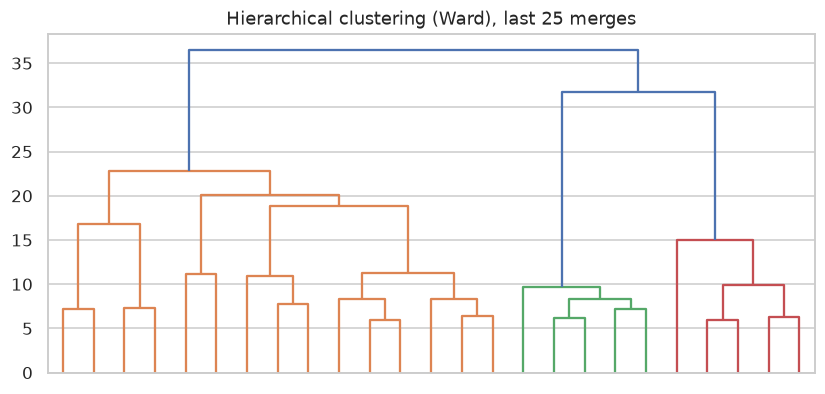

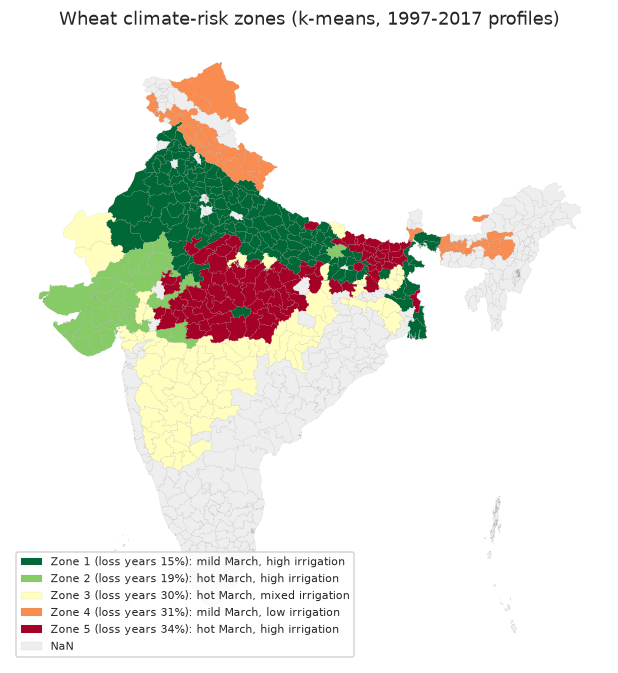

In [8]:
fig = plt.figure(figsize=(9, 4))
Zl = linkage(X, method="ward"); dendrogram(Zl, truncate_mode="lastp", p=25, no_labels=True)
plt.title("Hierarchical clustering (Ward), last 25 merges"); save(fig, "07_dendrogram"); plt.show()
g = geo.merge(W[["zone"]].reset_index().rename(columns={"unit_id": "district_id"}), on="district_id", how="left")
fig, ax = plt.subplots(figsize=(7, 7.5))
g.plot(column="zone", categorical=True, legend=True, cmap="RdYlGn_r", ax=ax, linewidth=.05, edgecolor="grey",
       missing_kwds=dict(color="#eeeeee"), legend_kwds=dict(loc="lower left", fontsize=7))
ax.set_axis_off(); ax.set_title("Wheat climate-risk zones (k-means, 1997-2017 profiles)")
save(fig, "07_map_risk_zones"); plt.show()

## 5. Graph-based semi-supervised learning: label propagation
Only 368 districts have enough wheat years to judge their risk. Can we estimate a risk label for the other districts
from **climate similarity**? Build a k-nearest-neighbour graph on the climate profile (available for 637 districts),
put the known labels on their nodes, and let labels **spread along the edges** to unlabelled neighbours
(`LabelSpreading`: a node's label is a smoothed mix of its neighbours' labels).

Label: **high risk** = loss years in at least 30% of years (1997-2017).
**Validation first:** hide 30% of the known labels, propagate, and check how often the hidden ones come back right.

In [9]:
ccols = ["hot_days_mean", "hot_days_sd", "mar_tmax_mean", "tmin_mean", "rain_mean", "rain_cv"]
Xc = StandardScaler().fit_transform(P[ccols])
known = P.loss_share.notna().to_numpy()
y_true = np.where(known, (P.loss_share >= 0.30).astype(int), -1)     # -1 = unlabelled
print(f"labelled districts: {known.sum()} (high-risk share {y_true[known].mean():.2f}); unlabelled: {(~known).sum()}")

rng = np.random.default_rng(SEED); res = []
lab_idx = np.where(known)[0]
for rep in range(30):
    hide = rng.choice(lab_idx, size=int(.3 * len(lab_idx)), replace=False)
    y = y_true.copy(); y[hide] = -1
    ls = LabelSpreading(kernel="knn", n_neighbors=10, alpha=0.2).fit(Xc, y)
    keep = np.setdiff1d(lab_idx, hide)
    knn = KNeighborsClassifier(n_neighbors=10).fit(Xc[keep], y_true[keep])        # supervised-only comparison
    res.append({"label_spreading": balanced_accuracy_score(y_true[hide], ls.transduction_[hide]),
                "knn_supervised": balanced_accuracy_score(y_true[hide], knn.predict(Xc[hide])),
                "majority_baseline": 0.5})
R = pd.DataFrame(res)
print("balanced accuracy on hidden labels (30 repeats):"); print(R.agg(["mean", "std"]).round(3).to_string())

labelled districts: 368 (high-risk share 0.29); unlabelled: 269


balanced accuracy on hidden labels (30 repeats):
      label_spreading  knn_supervised  majority_baseline
mean            0.638           0.591                0.5
std             0.034           0.031                0.0


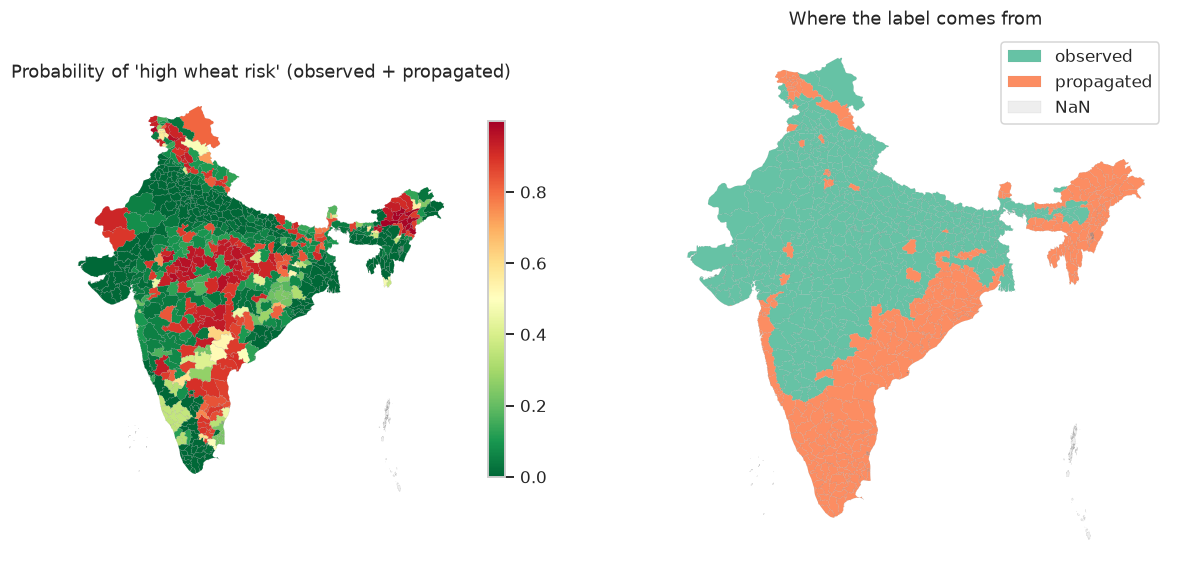

In [10]:
ls = LabelSpreading(kernel="knn", n_neighbors=10, alpha=0.2).fit(Xc, y_true)
P["risk_prob_high"] = ls.label_distributions_[:, 1]
P["risk_label_source"] = np.where(known, "observed", "propagated")
g = geo.merge(P[["risk_prob_high", "risk_label_source"]].reset_index().rename(columns={"unit_id": "district_id"}), on="district_id", how="left")
fig, ax = plt.subplots(1, 2, figsize=(13, 7))
g.plot(column="risk_prob_high", cmap="RdYlGn_r", legend=True, ax=ax[0], linewidth=.05, edgecolor="grey", missing_kwds=dict(color="#eeeeee"),
       legend_kwds=dict(shrink=.6)); ax[0].set_title("Probability of 'high wheat risk' (observed + propagated)")
g.plot(column="risk_label_source", categorical=True, legend=True, ax=ax[1], cmap="Set2", linewidth=.05, edgecolor="grey",
       missing_kwds=dict(color="#eeeeee")); ax[1].set_title("Where the label comes from")
for a in ax: a.set_axis_off()
save(fig, "07_map_label_propagation"); plt.show()

**How to read this:** propagated values are *climate-based guesses* for districts with little or no wheat data; they are
only as good as the validation score above, and they say "climatically similar to high-risk wheat districts", not
"has high yield losses". Districts that do not grow wheat have no yield risk in reality.

## 6. Feature selection for the prediction models (training years only)
Target: wheat relative yield anomaly from the **train-only trend** (`detrend_train_only`), years 1997-2017.
Features are within-district deviations from their **training-period** district means. Four views:
1. **Redundancy:** correlation and VIF (variance inflation factor; VIF > 10 = severe multicollinearity).
2. **Mutual information** (any kind of dependence, not just linear).
3. **Lasso (L1)**: shrinks weak coefficients exactly to 0; penalty chosen by year-grouped CV.
4. **Random forest permutation importance**, cross-validated by year groups.

In [11]:
m = pd.read_parquet(PROCESSED / "model_wheat.parquet")
m = detrend_train_only(m[m.in_sample])
tr = m[m.year <= TRAIN_LAST_YEAR].copy()
cand = ["tmax_mean", "tmin_mean", "gdd", "edd", "mar_tmax_mean", "mar_hot_days_35", "edd_mar",
        "rain_total", "rain_nov_jan", "rainy_days", "rain_cv_monthly", "irr_share"]
tr = tr.dropna(subset=cand + ["yield_rel_anom_train"])
Xf = tr[cand] - tr.groupby("unit_id")[cand].transform("mean")    # within-district deviations (training years only)
yf = tr.yield_rel_anom_train
print(f"training rows: {len(tr):,} (years {tr.year.min()}-{tr.year.max()})")
vif = pd.Series([variance_inflation_factor(Xf.values, i) for i in range(len(cand))], index=cand)
mi = pd.Series(mutual_info_regression(Xf, yf, random_state=SEED), index=cand)
cv = GroupKFold(n_splits=5)
las = LassoCV(cv=list(cv.split(Xf, yf, groups=tr.year)), random_state=SEED).fit(StandardScaler().fit_transform(Xf), yf)
lasso = pd.Series(las.coef_, index=cand)
pi = []
for trn, val in cv.split(Xf, yf, groups=tr.year):
    rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=SEED).fit(Xf.iloc[trn], yf.iloc[trn])
    pi.append(permutation_importance(rf, Xf.iloc[val], yf.iloc[val], n_repeats=5, random_state=SEED).importances_mean)
perm = pd.Series(np.mean(pi, axis=0), index=cand)
FS = pd.DataFrame({"VIF": vif, "mutual_info": mi, "lasso_coef(std)": lasso, "rf_perm_importance": perm})
FS["votes"] = (FS.mutual_info.rank(ascending=False) <= 6).astype(int) + (FS["lasso_coef(std)"].abs() > 1e-6).astype(int) \
              + (FS.rf_perm_importance.rank(ascending=False) <= 6).astype(int)
print(FS.sort_values("votes", ascending=False).round(4).to_string())

training rows: 6,103 (years 1998-2017)


                      VIF  mutual_info  lasso_coef(std)  rf_perm_importance  votes
tmin_mean         24.1764       0.0562          -0.0264             -0.0015      3
gdd              101.3224       0.0586          -0.0000              0.0297      2
rain_total         4.1321       0.0310           0.0000             -0.0065      2
mar_tmax_mean      3.3935       0.0495           0.0000              0.0084      2
rain_cv_monthly    1.1223       0.0182           0.0000             -0.0042      1
tmax_mean         47.5870       0.0362          -0.0000             -0.0262      1
edd_mar           26.9493       0.0274           0.0000             -0.0115      1
irr_share          1.0104       0.0186          -0.0000             -0.0016      1
edd               22.0189       0.0127          -0.0000             -0.0166      0
mar_hot_days_35    4.8321       0.0261          -0.0000             -0.0093      0
rainy_days         4.1842       0.0074          -0.0000             -0.0076      0
rain

In [12]:
# Keep features with >= 2 of 3 votes, then drop the more redundant member of any pair with |r| > 0.85
sel = FS[FS.votes >= 2].sort_values("rf_perm_importance", ascending=False).index.tolist()
corr = Xf[sel].corr().abs(); final = []
for f in sel:
    if all(corr.loc[f, g] <= 0.85 for g in final):
        final.append(f)
print("selected:", final)
json.dump({"wheat": final, "candidates": cand, "rule": ">=2 of 3 votes (MI top-6, Lasso nonzero, RF permutation top-6), drop |r|>0.85"},
          open(PROCESSED / "selected_features.json", "w"), indent=2)
W[["zone"]].to_csv(PROCESSED / "risk_zones_wheat.csv")
P[["risk_prob_high", "risk_label_source"]].to_csv(PROCESSED / "risk_propagated_wheat.csv")

selected: ['gdd', 'mar_tmax_mean', 'tmin_mean', 'rain_total']


## 7. What Phase 7 found (written after reviewing outputs)
Method choices: DECISIONS.md, D17.